# Starter notebook: multimodal representations of a CRISPR screen

This notebook loads the tables of the Element Biosciences Cytos screen, where RNA, protein and cell painting were measured in the same 258,896 A549 cells. It builds one embedding from all three modalities. It runs on a laptop in a few minutes and needs about 4 GB of memory.

The README describes the experimental design and every column.

In [1]:
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DATA = Path("data")
URL = "https://exampledata.scverse.org/sbi2-cytodata/multiomics"
SHA256 = {  # 2.4 GB together
    "rna.h5ad": "a570888a00a0a98fd7b47ebace10f576fb04775b44732159ff419a81710bd293",
    "imaging.h5ad": "045854ba23a19bccb89615ab215ea9db92bd76050425ee3cdcbd31b115a652b4",
    "guides.h5ad": "add7668236e6fab989315851c11d578d9db49c935d9b06ea4363c46bd06bc618",
}

# pooch skips files that are already there and checks each download against its checksum
for name, sha in SHA256.items():
    pooch.retrieve(f"{URL}/{name}", known_hash=f"sha256:{sha}", fname=name, path=DATA)

## Load the tables

The three files share the same rows in the same order, so row `i` is the same cell in every file. We open the files without loading their matrices, keep the cells that pass QC (`qc_fail` is false; it combines all QC flags), and load a random sample of 20,000 of them, which keeps memory and runtime low.

In [2]:
rna_all = ad.read_h5ad(DATA / "rna.h5ad", backed="r")
img_all = ad.read_h5ad(DATA / "imaging.h5ad", backed="r")
assert (rna_all.obs_names == img_all.obs_names).all()

obs = rna_all.obs
pd.crosstab(obs["target_gene"], [obs["condition"], obs["qc_fail"]])

condition      TNFa       baseline      
qc_fail       False True     False True 
target_gene                             
CTNNB1        22058  5115    23290  5147
GSK3B         17160  4592    16792  4581
IL1R1          6618  1388     7109  1561
NTC           13263  3300    13680  3336
OR1I1         33867  6866    35058  6605
SMAD7          5060  1067     5115  1156
TGFBR2         3444   699     3577   619
Undetermined      0  3523        0  3250

In [3]:
rng = np.random.default_rng(0)
cells = np.sort(rng.choice(np.flatnonzero(~obs["qc_fail"]), 20_000, replace=False))
rna = rna_all[cells].to_memory()
img = img_all[cells].to_memory()
obs = rna.obs

## Split the imaging table into protein and cell painting

Each imaging feature has a `modality` in `var`: `cell_paint`, `protein`, `shape`, `control` (IgG) or `background`. The imaging matrix was normalised with mantispy: each feature is a robust z-score against all non-targeting cells, and `var["selected"]` marks the features that mantispy's feature selection kept. The raw values are in `layers["raw"]`. We use the selected protein features as one block, and the selected cell painting and shape features as another.

In [4]:
selected, modality = img.var["selected"], img.var["modality"]
protein = img[:, selected & (modality == "protein")].to_df()
paint = img[:, selected & modality.isin(["cell_paint", "shape"])].to_df()
print(f"protein: {protein.shape[1]} features, cell painting: {paint.shape[1]} features")

protein: 163 features, cell painting: 206 features


## One PCA per modality

For RNA we normalise the counts, log-transform them and keep 2,000 highly variable genes. The image features are already normalised, so we only fill the few missing values and clip extreme values. Each modality then gets its own PCA.

In [5]:
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=2000)
rna_hvg = rna[:, rna.var["highly_variable"]].X.toarray()


def clean(df):
    return df.fillna(0).clip(-10, 10).to_numpy()


blocks = {
    "rna": StandardScaler().fit_transform(rna_hvg),
    "protein": clean(protein),
    "paint": clean(paint),
}
n_pcs = {"rna": 30, "protein": 10, "paint": 30}
pcs = {k: PCA(n_pcs[k], random_state=0).fit_transform(x) for k, x in blocks.items()}

## Joint embedding

We scale each block of principal components so that each modality has the same total variance, and then concatenate the blocks. This step keeps any single modality from dominating the embedding just because it has more features. We then compute one UMAP for the joint embedding and one for each modality, so you can compare them.

In [6]:
joint = np.hstack([p / np.sqrt((p**2).sum(1).mean()) for p in pcs.values()])

emb = sc.AnnData(obs=obs[["Well", "condition", "target_gene", "guide"]].copy())
for name, x in {**pcs, "joint": joint}.items():
    emb.obsm[f"X_{name}"] = x
    sc.pp.neighbors(emb, use_rep=f"X_{name}", key_added=name, transformer="sklearn")
    emb.obsm[f"X_umap_{name}"] = sc.tl.umap(emb, neighbors_key=name, copy=True).obsm["X_umap"]

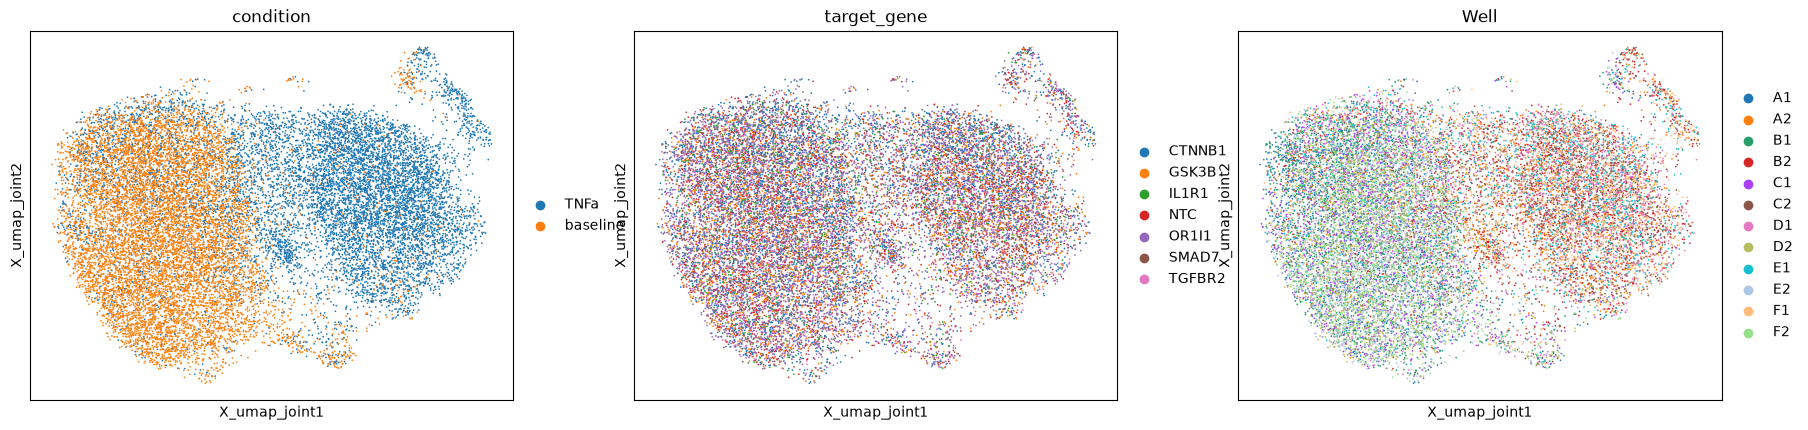

In [7]:
sc.pl.embedding(emb, "X_umap_joint", color=["condition", "target_gene", "Well"], ncols=3)

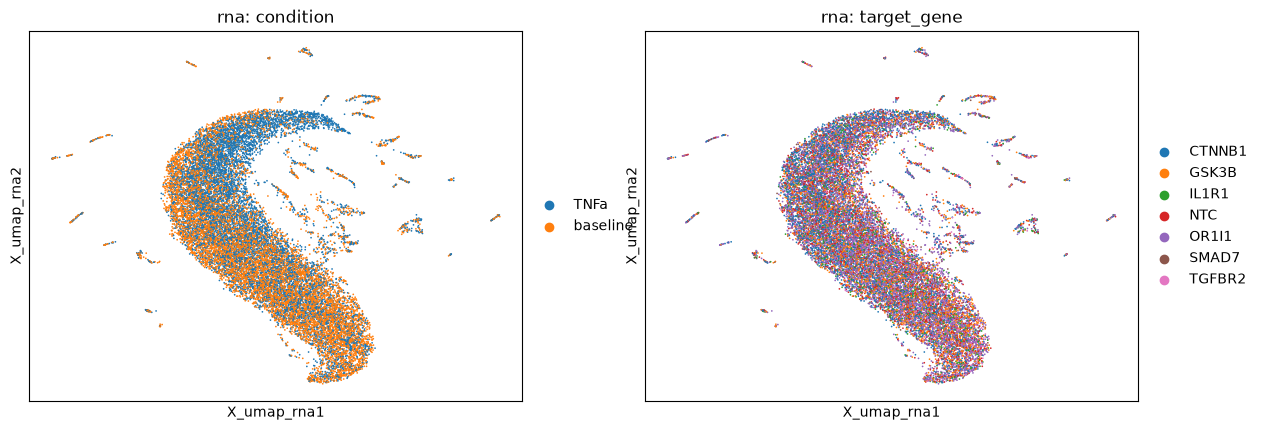

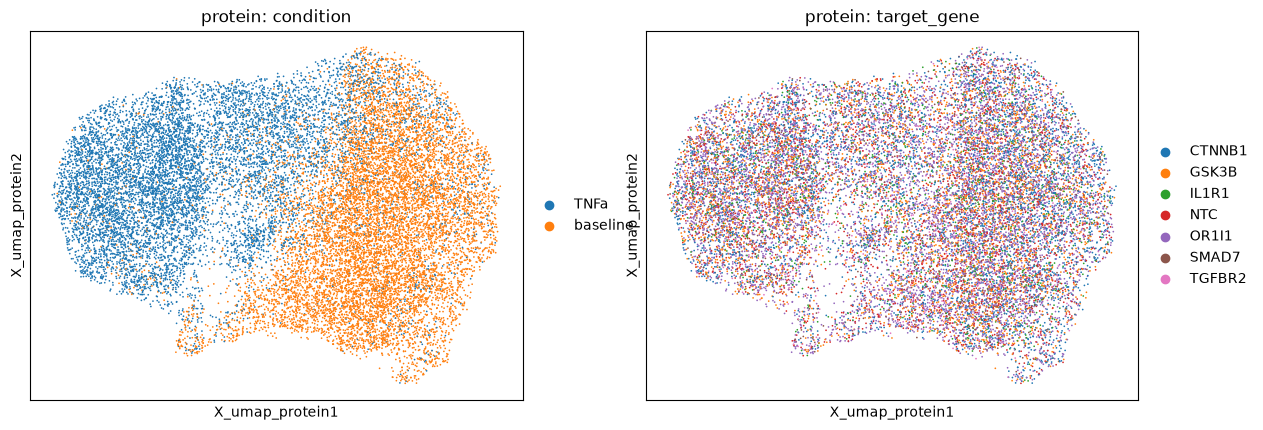

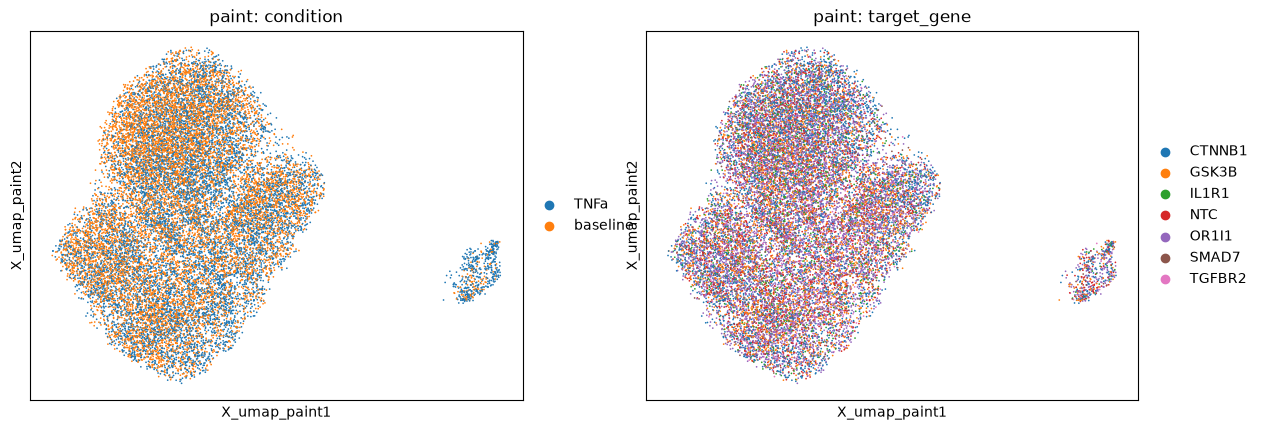

In [8]:
for name in ["rna", "protein", "paint"]:
    sc.pl.embedding(emb, f"X_umap_{name}", color=["condition", "target_gene"], title=[f"{name}: condition", f"{name}: target_gene"])

## Baseline scores

We score each embedding on two tasks with a k-nearest-neighbour classifier and 5-fold cross-validation. The score is the balanced accuracy, where 0.5 means the embedding doesn't separate the groups at all and 1.0 means it separates them perfectly. The first task asks whether TNFα-treated cells separate from untreated cells. The second task asks, for each knockout and within each condition, whether knockout cells separate from non-targeting cells. A better representation should beat the joint row.

In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier


def knn_score(x, y):
    return cross_val_score(KNeighborsClassifier(15), x, y, cv=5, scoring="balanced_accuracy").mean()


KNOCKOUTS = ["TGFBR2", "SMAD7", "IL1R1", "GSK3B", "CTNNB1", "OR1I1"]
scores = {}
for name in ["rna", "protein", "paint", "joint"]:
    x = emb.obsm[f"X_{name}"]
    row = {"TNFa vs baseline": knn_score(x, obs["condition"])}
    for ko in KNOCKOUTS:
        per_condition = []
        for condition in ["baseline", "TNFa"]:
            m = ((obs["condition"] == condition) & obs["target_gene"].isin([ko, "NTC"])).values
            per_condition.append(knn_score(x[m], np.asarray(obs["target_gene"], dtype=str)[m]))
        row[f"{ko} vs NTC"] = np.mean(per_condition)
    scores[name] = row
pd.DataFrame(scores).T.round(3)

,TNFa vs baseline,TGFBR2 vs NTC,SMAD7 vs NTC,IL1R1 vs NTC,GSK3B vs NTC,CTNNB1 vs NTC,OR1I1 vs NTC
rna,0.771,0.506,0.498,0.499,0.496,0.556,0.504
protein,0.920,0.505,0.506,0.505,0.505,0.530,0.500
paint,0.617,0.514,0.500,0.490,0.515,0.525,0.501
joint,0.911,0.516,0.495,0.497,0.519,0.542,0.501


Single cells barely separate by knockout, even though the TGFBR2 knockout is clearly visible when cells are pooled per well (see the box plot below). Finding single-cell representations that separate the knockouts is an open challenge.

We can also ask the question at the level of profiles: we average each embedding over the cells of each guide in each well, and use [mantispy](https://github.com/scverse/mantispy) to compute the phenotypic activity of each knockout. The activity is the mean average precision (mAP) with which a knockout's profiles retrieve each other against the non-targeting profiles of the same condition. A higher mAP means the knockout is more distinguishable from the non-targeting cells.

In [10]:
import mantispy as mt

profiles = obs[["Well", "guide", "target_gene", "condition"]].astype(str).copy()
groups = [profiles["Well"], profiles["guide"]]
meta = profiles.groupby(groups, observed=True).first().reset_index()
meta = meta.rename(columns={"Well": "Metadata_Well", "guide": "Metadata_Guide", "target_gene": "Metadata_Perturbation", "condition": "Metadata_Condition"})
meta["Metadata_Plate"] = "Cytos-MPS_TNFa"
means = {
    name: pd.DataFrame(emb.obsm[f"X_{name}"]).groupby([g.values for g in groups]).mean().to_numpy(np.float32)
    for name in ["rna", "protein", "paint", "joint"]
}
agg = ad.AnnData(X=means["joint"], obs=meta, obsm={f"X_{k}": v for k, v in means.items()})
mt.io.stamp(agg, resolution="aggregate", grouped_by=["Metadata_Well", "Metadata_Guide"], feature_kind="embedding")
mt.pp.annotate_controls(agg, negcon=["NTC"])

activity = {}
for name in ["rna", "protein", "paint", "joint"]:
    mt.tl.map(agg, mode="activity", batch="Metadata_Condition", use_rep=f"X_{name}", null_size=1000, key_added=f"map_{name}")
    table = agg.uns["mantispy"][f"map_{name}"]
    activity[name] = table.groupby("Metadata_Perturbation")["score"].mean()
pd.DataFrame(activity).T.round(3)

Metadata_Perturbation,CTNNB1,GSK3B,IL1R1,OR1I1,SMAD7,TGFBR2
rna,0.729,0.651,0.610,0.626,0.603,0.763
protein,0.643,0.579,0.531,0.607,0.521,0.542
paint,0.773,0.640,0.614,0.629,0.621,0.800
joint,0.653,0.598,0.535,0.614,0.517,0.606


OR1I1 isn't expressed in A549 cells, so its score shows roughly what a knockout without a phenotype gets. In these profiles, TGFBR2 and CTNNB1 score above OR1I1 in the RNA and cell painting embeddings, but less so in the joint embedding, so concatenating the modalities dilutes the knockout signal. The q-values are in `agg.uns["mantispy"]["map_joint"]`.

## Normalising per well

Each well is either untreated or treated with TNFα, so the condition is confounded with the well. The imaging matrix is therefore normalised against the non-targeting cells of the whole plate, which keeps the TNFα response. If you study knockout effects within one condition, you can instead normalise each well against its own non-targeting cells, which also removes differences in staining between wells, with [mantispy](https://github.com/scverse/mantispy):

```python
import mantispy as mt

per_well = img.copy()
per_well.X = per_well.layers["raw"].copy()
mt.pp.normalize(per_well, by="Metadata_Well", reference="negcon")
```

## A known perturbation in all modalities: TGFBR2 knockout

Knocking out TGFBR2 should lower the expression of TGF-β target genes. We compare TGFBR2 knockout cells with non-targeting (NTC) cells in each well, using all QC-passing cells, and we sum the raw counts per well (pseudobulk) so that we don't need to normalise the full matrix.

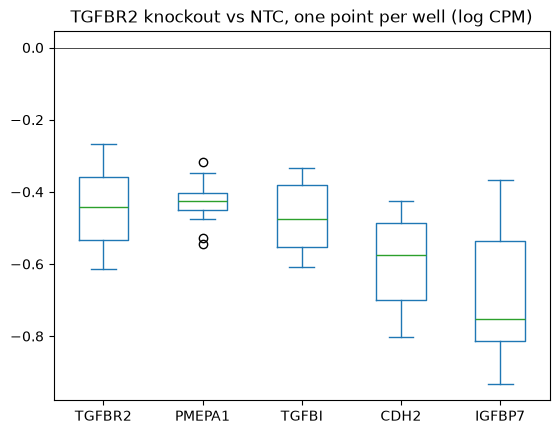

In [11]:
genes = ["TGFBR2", "PMEPA1", "TGFBI", "CDH2", "IGFBP7"]
keep = np.flatnonzero(~rna_all.obs["qc_fail"].values & rna_all.obs["target_gene"].isin(["TGFBR2", "NTC"]).values)
cols = rna_all.var_names.get_indexer(genes)
# read 5,000 cells at a time and keep only these genes, so memory stays low
x = np.vstack([rna_all.X[keep[i : i + 5000]][:, cols].toarray() for i in range(0, len(keep), 5000)])
sub = rna_all.obs.iloc[keep]
groups = [sub["Well"].values, sub["target_gene"].astype(str).values]
counts = pd.DataFrame(x, columns=genes).groupby(groups).sum()
depth = pd.Series(sub["rna_total_counts"].values).groupby(groups).sum()
cpm = np.log1p(counts.div(depth, axis=0) * 1e6)
log_fc = cpm.xs("TGFBR2", level=1) - cpm.xs("NTC", level=1)
ax = log_fc.plot.box(title="TGFBR2 knockout vs NTC, one point per well (log CPM)")
ax.axhline(0, color="k", lw=0.5);

In [12]:
feats = {"protein": protein, "cell painting": paint}
rows = []
for modality, df in feats.items():
    z = df.fillna(0)
    diff = z[obs["target_gene"] == "TGFBR2"].mean() - z[obs["target_gene"] == "NTC"].mean()
    rows.append(diff.abs().sort_values(ascending=False).head(5).rename(modality))
pd.concat(rows, axis=1)

,protein,cell painting
Granularity_8_ERK1_ERK2,0.985728,NaN
Texture_SumAverage_3_00_256_Phospho-HSP27,0.966886,NaN
Texture_SumAverage_3_00_256_ERK1_ERK2,0.862611,NaN
Texture_SumVariance_3_03_256_Phospho-HSP27,0.765361,NaN
Texture_SumVariance_3_01_256_ERK1_ERK2,0.714630,NaN
Granularity_8_Cell-Membrane,NaN,3.894555
Texture_Contrast_3_03_256_Cell-Membrane,NaN,1.585363
Granularity_7_Cell-Membrane,NaN,1.419781
Texture_SumVariance_3_01_256_Cell-Membrane,NaN,1.271472
Granularity_6_Cell-Membrane,NaN,0.986709


## Where to go from here

- Replace the concatenation with a multimodal model, e.g. MOFA or a multimodal autoencoder.
- Check whether the knockouts separate from NTC cells in each modality, and in the joint embedding.
- Predict one modality from another, e.g. RNA from the image features.
- Use the images in `subset_A1_A2.zarr.zip` or `full.zarr.zip` (SpatialData) to learn image features directly.